# KAN on a known-truth kinetics benchmark

The two chemistry notebooks ask whether a KAN's response curves can be read as chemistry. On real
data the truth is unknown, so this notebook builds a dataset from four textbook relationships with
literature constants and checks what the same pipeline recovers.

## The generating equations

A rate constant for a substituted aryl substrate reacting with a phosphine-ligated catalyst at
temperature $T$:

$$\log_{10} k = \log_{10} k_0 + \rho\,\sigma_p
\;-\;\frac{\Delta H^\ddagger}{2.303\,R}\left(\frac{1}{T}-\frac{1}{298.15}\right)
\;-\;\Delta\,\mathrm{sigmoid}\!\left(\frac{\%V_\mathrm{bur}(\min)-32}{w}\right)
\;-\;a\,(\Delta E_\mathrm{bind}-\Delta E_\mathrm{opt})^2 + \varepsilon$$

| Term | Law | Constants | Shape the pipeline should find |
|---|---|---|---|
| $\rho\,\sigma_p$ | Hammett | $\rho = 1.5$; $\sigma_p$ of 12 common substituents (NO$_2$ 0.78 to NMe$_2$ -0.83) | Linear |
| $-\Delta H^\ddagger/(2.303\,R)\,(1/T - 1/298.15)$ | Eyring/Arrhenius | $\Delta H^\ddagger = 15$ kcal/mol, $T$ from 288 to 368 K | Monotone, concave in $T$ |
| $-\Delta\,\mathrm{sigmoid}((\%V_\mathrm{bur}(\min)-32)/w)$ | Ligation-state cliff (Science 2021) | $\Delta = 1.5$ log units, $w = 1$ % | Step down near 32 % |
| $-a\,(\Delta E_\mathrm{bind}-\Delta E_\mathrm{opt})^2$ | Sabatier volcano | $a = 0.01$, $\Delta E_\mathrm{opt} = -15$ kcal/mol | Inverted U with the top at -15 |
| `noise_descriptor` | none | standard normal, unrelated to $k$ | Constant |

The noise $\varepsilon$ is normal with sd 0.15 log units. A second target replaces the Hammett
term with a mechanism break (different $\rho$ on each side of $\sigma = 0$, the classic
V-shaped Hammett plot); section 5 tests it separately.

## What this notebook does

Every dataset notebook in this series runs the same pipeline from `pycse.sklearn.kan_interpret`,
so the results are comparable across chemistries:

1. **Models on identical folds.** A linear baseline, random forest, gradient boosting and a KAN
   scored by 5x3 repeated cross-validation with the scaler refit inside each fold, and a paired
   Wilcoxon test of the KAN against the best other model.
2. **Single-descriptor thresholds.** Class-balanced stumps scored by balanced accuracy, with the
   majority baseline, so a "rule" that only predicts the majority class scores 0.5.
3. **Partial effects with fold envelopes.** One-descriptor response curves of the KAN in the
   descriptor's own units, with the linear baseline on the same grid and the envelope of five
   refits. A shape that changes from fold to fold is not a finding.
4. **A check against the known chemistry.** What the source paper established, or (for the
   synthetic benchmark) the generating equations, overlaid on what the pipeline recovered.

No emoji, no claims from a single fit.


In [1]:
import os

os.environ["JAX_PLATFORM_NAME"] = "cpu"
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    RandomForestClassifier,
    GradientBoostingClassifier,
)
from sklearn.metrics import r2_score, mean_absolute_error, roc_auc_score, accuracy_score

from pycse.sklearn.kan import KAN
from pycse.sklearn.kan_interpret import (
    classify_shape,
    cv_compare,
    partial_effects,
    partial_effects_cv,
    plot_fold_scores,
    plot_partial_effect,
    sensitivity,
    threshold_rules,
)
from pycse.sklearn._plotstyle import (
    INK,
    INK_2,
    MUTED,
    BASELINE,
    SURFACE,
    SERIES,
    PX,
    style_axes,
    finish_axes,
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Record the environment: KAN fits move slightly between jax/XLA builds.
import importlib.metadata as _md

print(
    "Versions:",
    ", ".join(
        f"{p} {_md.version(p)}" for p in ("pycse", "jax", "optax", "numpy", "scikit-learn", "scipy")
    ),
)


Versions: pycse 2.13.0, jax 0.12.0.1, optax 0.2.8, numpy 2.5.4, scikit-learn 1.9.1, scipy 1.18.1


## 1. Build the dataset

600 reactions: substituents drawn from the 12-entry Hammett table, the other descriptors uniform
over their ranges. The truth terms are kept as functions so they can be overlaid on the recovered
curves later.


In [2]:
R_CAL = 1.987e-3  # kcal/(mol K)
SIGMA_P = {
    "NO2": 0.78, "CN": 0.66, "CF3": 0.54, "CO2Me": 0.45, "Cl": 0.23, "Br": 0.23,
    "F": 0.06, "H": 0.00, "Me": -0.17, "tBu": -0.20, "OMe": -0.27, "NMe2": -0.83,
}  # fmt: skip
RHO, DH_ACT, CLIFF_DROP, CLIFF_W, VOLCANO_A, E_OPT = 1.5, 15.0, 1.5, 1.0, 0.01, -15.0
LOG_K0, NOISE_SD, N = -3.0, 0.15, 600


def term_hammett(s):
    return RHO * s


def term_eyring(T):
    return -DH_ACT / (2.303 * R_CAL) * (1.0 / T - 1.0 / 298.15)


def term_cliff(v):
    return -CLIFF_DROP / (1.0 + np.exp(-(v - 32.0) / CLIFF_W))


def term_volcano(e):
    return -VOLCANO_A * (e - E_OPT) ** 2


def term_none(z):
    return np.zeros_like(np.asarray(z, dtype=float))


TRUTH = {
    "sigma_p": term_hammett,
    "T_K": term_eyring,
    "pct_Vbur_min": term_cliff,
    "dE_bind": term_volcano,
    "noise_descriptor": term_none,
}

rng = np.random.default_rng(2021)
subst = rng.choice(list(SIGMA_P), size=N)
df = pd.DataFrame(
    {
        "substituent": subst,
        "sigma_p": [SIGMA_P[s] for s in subst],
        "T_K": rng.uniform(288.0, 368.0, N),
        "pct_Vbur_min": rng.uniform(22.0, 50.0, N),
        "dE_bind": rng.uniform(-30.0, 0.0, N),
        "noise_descriptor": rng.normal(size=N),
    }
)
df["log10_k"] = LOG_K0 + sum(TRUTH[f](df[f].to_numpy()) for f in TRUTH) + rng.normal(0, NOISE_SD, N)

X_df = df[list(TRUTH)]
y = df["log10_k"].to_numpy()
TASK = "regression"
Y_LABEL = "log10 k"
COMPONENT = {"sigma_p": "substrate", "T_K": "conditions", "pct_Vbur_min": "ligand", "dE_bind": "catalyst", "noise_descriptor": "none"}
SUCCESS = (y > np.median(y)).astype(int)
SUCCESS_RULE = "log10 k above the median"
display(df.head())


,substituent,sigma_p,T_K,pct_Vbur_min,dE_bind,noise_descriptor,log10_k
0,tBu,-0.20,327.615847,30.059084,-19.834695,1.072492,-3.091883
1,tBu,-0.20,351.171422,30.250365,-23.624701,0.732806,-2.552929
2,Br,0.23,311.291715,49.162883,-17.330664,-0.242474,-3.654478
3,NMe2,-0.83,300.464851,34.633344,-23.203925,-0.559901,-6.348026
4,H,0.00,316.280646,41.681293,-5.843115,0.396553,-4.913302


600 reactions, 5 descriptors. Target: log10 k (regression).
Success for the threshold rules: log10 k above the median (50% of reactions).


,Component,Distinct,Min,Max
sigma_p,substrate,11,-0.830,0.780
T_K,conditions,600,288.069,367.919
pct_Vbur_min,ligand,600,22.003,49.949
dE_bind,catalyst,600,-29.992,-0.191
noise_descriptor,none,600,-4.367,2.652


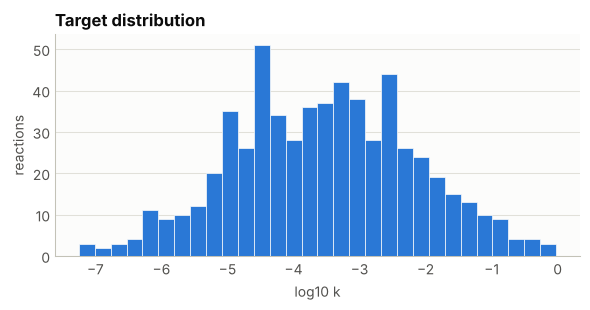

In [3]:
feature_names = list(X_df.columns)
X = X_df.to_numpy(dtype=float)
y = np.asarray(y, dtype=float)
SUCCESS = np.asarray(SUCCESS, dtype=int)
n_features = len(feature_names)
COMPONENTS = list(dict.fromkeys(COMPONENT[f] for f in feature_names))
COMP_COLOR = {c: SERIES[k % len(SERIES)] for k, c in enumerate(COMPONENTS)}

desc = pd.DataFrame(
    {
        "Component": [COMPONENT[f] for f in feature_names],
        "Distinct": X_df.nunique().values,
        "Min": X_df.min().values,
        "Max": X_df.max().values,
    },
    index=feature_names,
)
print(f"{len(X)} reactions, {n_features} descriptors. Target: {Y_LABEL} ({TASK}).")
print(f"Success for the threshold rules: {SUCCESS_RULE} ({SUCCESS.mean():.0%} of reactions).")
display(desc.round(3))

fig, ax = plt.subplots(figsize=(6, 3.2))
style_axes(ax)
if TASK == "regression":
    ax.hist(y, bins=30, color=SERIES[0], edgecolor=SURFACE, linewidth=0.5)
    finish_axes(ax, "Target distribution", Y_LABEL, "reactions")
else:
    vals, counts = np.unique(y, return_counts=True)
    ax.bar(vals, counts, width=0.6, color=[MUTED, SERIES[0]], linewidth=0)
    ax.set_xticks(vals)
    ax.set_xticklabels([f"{int(v)} ({c})" for v, c in zip(vals, counts)])
    finish_axes(ax, "Class balance", Y_LABEL, "reactions")
plt.tight_layout()
plt.show()


## 2. Models on identical folds

The four models see exactly the same 15 folds (5 splits x 3 repeats, scaler refit per fold).
The paired comparison asks a narrow question: on the same held-out reactions, is the KAN better
than the best of the other models, and how often?


Model                  r2               other
MLR                    0.673 ± 0.036   0.647 ± 0.027 (mae)
Random Forest          0.912 ± 0.016   0.317 ± 0.024 (mae)
Gradient Boosting      0.963 ± 0.006   0.209 ± 0.014 (mae)
KAN                    0.984 ± 0.004   0.136 ± 0.011 (mae)
KAN vs Gradient Boosting, paired over 15 folds: Δr2 = +0.0210 ± 0.0053, KAN better in 15/15, Wilcoxon p = 6.1e-05
(93 s)


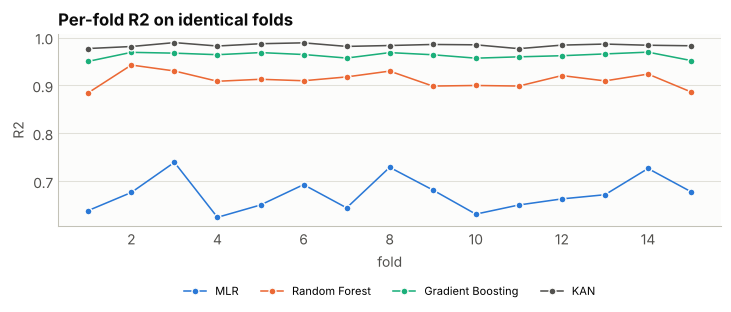

In [4]:
# One hidden layer; width 8 and 5 knots on datasets of 1000 reactions or more,
# 4 and 3 below that, so the spline count stays in proportion to the data.
WIDE = len(X) >= 1000
KAN_LAYERS = (n_features, 8 if WIDE else 4, 1)
KAN_GRID = 5 if WIDE else 3
KAN_MAXITER = 300
CV_SPLITS, CV_REPEATS, CV_SEED = 5, 3, 42


def make_kan():
    return KAN(layers=KAN_LAYERS, grid_size=KAN_GRID, spline_order=3)


def make_models():
    """Fresh models; the ensembles use the settings of the first two chemistry notebooks."""
    if TASK == "regression":
        return {
            "MLR": LinearRegression(),
            "Random Forest": RandomForestRegressor(
                n_estimators=300, max_depth=12, min_samples_split=5, min_samples_leaf=2,
                random_state=42, n_jobs=-1,
            ),  # fmt: skip
            "Gradient Boosting": GradientBoostingRegressor(
                n_estimators=300, learning_rate=0.1, max_depth=4, min_samples_split=5,
                min_samples_leaf=3, subsample=0.8, random_state=42,
            ),  # fmt: skip
            "KAN": make_kan(),
        }
    return {
        "Logistic": LogisticRegression(max_iter=2000),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, max_depth=12, min_samples_split=5, min_samples_leaf=2,
            random_state=42, n_jobs=-1,
        ),  # fmt: skip
        "Gradient Boosting": GradientBoostingClassifier(
            n_estimators=300, learning_rate=0.1, max_depth=4, min_samples_split=5,
            min_samples_leaf=3, subsample=0.8, random_state=42,
        ),  # fmt: skip
        "KAN": make_kan(),
    }


BASELINE_NAME = "MLR" if TASK == "regression" else "Logistic"

t0 = time.time()
cv_result = cv_compare(
    make_models(),
    X,
    y,
    task=TASK,
    n_splits=CV_SPLITS,
    n_repeats=CV_REPEATS,
    random_state=CV_SEED,
    fit_kwargs={"KAN": {"maxiter": KAN_MAXITER}},
    verbose=False,
)
print(cv_result)
print(f"({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
plot_fold_scores(ax, cv_result)
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.25))
plt.tight_layout()
plt.show()


Held-out split: 480 train / 120 test


,Test R2,Test MAE
Model,,
MLR,0.639,0.614
Random Forest,0.887,0.354
Gradient Boosting,0.953,0.226
KAN,0.977,0.153


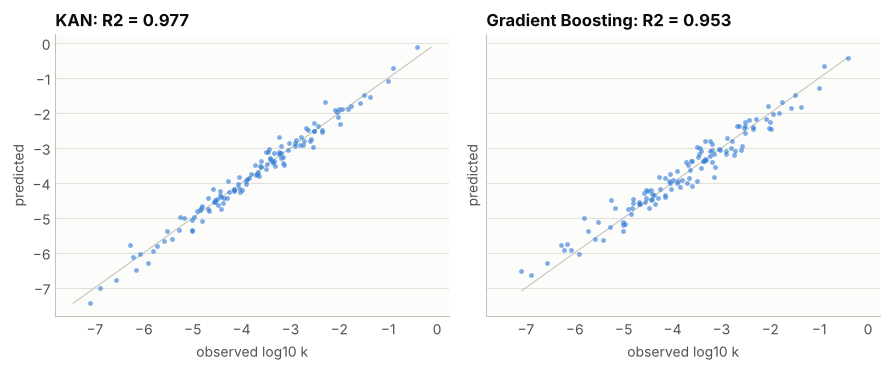

In [5]:
# One held-out split for the models the rest of the notebook interprets.
strat = y.astype(int) if TASK == "classification" else None
idx_tr, idx_te = train_test_split(np.arange(len(X)), test_size=0.2, random_state=42, stratify=strat)
scaler = StandardScaler().fit(X[idx_tr])
X_tr, X_te = scaler.transform(X[idx_tr]), scaler.transform(X[idx_te])
y_tr, y_te = y[idx_tr], y[idx_te]

fitted, rows = {}, []
for name, model in make_models().items():
    if name == "KAN":
        model.fit(X_tr, y_tr, maxiter=KAN_MAXITER)
    else:
        model.fit(X_tr, y_tr.astype(int) if TASK == "classification" else y_tr)
    fitted[name] = model
    if TASK == "regression":
        p = model.predict(X_te)
        rows.append({"Model": name, "Test R2": r2_score(y_te, p), "Test MAE": mean_absolute_error(y_te, p)})
    else:
        p = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else np.clip(model.predict(X_te), 0, 1)
        rows.append({"Model": name, "Test AUC": roc_auc_score(y_te, p), "Test accuracy": accuracy_score(y_te, (p > 0.5).astype(int))})
kan, baseline = fitted["KAN"], fitted[BASELINE_NAME]


def model_means(labels, model=None):
    """Observed and predicted mean target per group, over the training reactions.

    A partial effect fixes the other descriptors at their mean, which is not a real
    compound; to compare a model with observed group means, average its predictions
    over the reactions that were actually run.
    """
    model = model or kan
    pred = np.ravel(model.predict(X_tr))
    lab = np.asarray(labels)[idx_tr]
    return (
        pd.DataFrame({"label": lab, "observed": y[idx_tr], "predicted": pred})
        .groupby("label")
        .agg(observed=("observed", "mean"), predicted=("predicted", "mean"), n=("observed", "size"))
    )
headline = pd.DataFrame(rows).set_index("Model")
print(f"Held-out split: {len(idx_tr)} train / {len(idx_te)} test")
display(headline.round(3))

# The KAN against the best other model on the held-out reactions
metric = "Test R2" if TASK == "regression" else "Test AUC"
best_other = headline.drop("KAN")[metric].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharex=True, sharey=True)
for ax, name in zip(axes, ["KAN", best_other]):
    style_axes(ax)
    m = fitted[name]
    if TASK == "regression":
        p = m.predict(X_te)
        lim = [min(y_te.min(), p.min()), max(y_te.max(), p.max())]
        ax.plot(lim, lim, color=BASELINE, linewidth=PX, zorder=1)
        ax.scatter(y_te, p, s=12, color=SERIES[0], alpha=0.6, linewidths=0, zorder=2)
        finish_axes(ax, f"{name}: R2 = {headline.loc[name, metric]:.3f}", f"observed {Y_LABEL}", "predicted")
    else:
        p = m.predict_proba(X_te)[:, 1] if hasattr(m, "predict_proba") else np.clip(m.predict(X_te), 0, 1)
        bins = np.linspace(0, 1, 21)
        ax.hist(p[y_te == 0], bins=bins, color=MUTED, alpha=0.7, label="observed 0", linewidth=0)
        ax.hist(p[y_te == 1], bins=bins, color=SERIES[0], alpha=0.7, label="observed 1", linewidth=0)
        ax.legend(frameon=False, fontsize=8)
        finish_axes(ax, f"{name}: AUC = {headline.loc[name, metric]:.3f}", "predicted probability", "reactions")
plt.tight_layout()
plt.show()


## 3. Single-descriptor thresholds

The Doyle and Sigman groups look for reactivity cliffs with one cut on one descriptor. The same
search here: a depth-1 tree with balanced class weights on each descriptor, scored on the held-out
reactions by balanced accuracy. A descriptor with no information scores 0.5 whatever the class
balance.


Majority-class accuracy on the test reactions: 0.533
Balanced-accuracy baseline for guessing: 0.500


,Feature,Threshold,Balanced_Acc,Accuracy,Precision,Recall
0,T_K,323.146,0.729,0.725,0.677,0.786
1,sigma_p,0.145,0.682,0.683,0.661,0.661
2,pct_Vbur_min,32.649,0.650,0.658,0.674,0.518
3,dE_bind,-24.958,0.593,0.575,0.527,0.857
4,noise_descriptor,-1.509,0.519,0.492,0.477,0.929


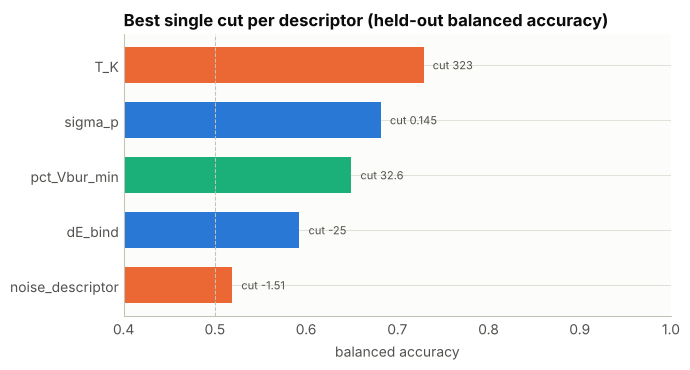

In [6]:
rules = threshold_rules(X[idx_tr], SUCCESS[idx_tr], feature_names, X[idx_te], SUCCESS[idx_te])
print(f"Majority-class accuracy on the test reactions: {rules.attrs['majority_accuracy']:.3f}")
print("Balanced-accuracy baseline for guessing: 0.500")
display(rules.head(10).round(3))

top = rules.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 3.8))
style_axes(ax)
ax.barh(top.Feature, top.Balanced_Acc, color=[COMP_COLOR[COMPONENT[f]] for f in top.Feature], height=0.65, linewidth=0)
ax.axvline(0.5, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0.4, 1.0)
for yk, (f, b, t) in enumerate(zip(top.Feature, top.Balanced_Acc, top.Threshold)):
    ax.text(b + 0.01, yk, f"cut {t:.3g}", va="center", fontsize=8, color=INK_2)
finish_axes(ax, "Best single cut per descriptor (held-out balanced accuracy)", "balanced accuracy", "")
plt.tight_layout()
plt.show()


## 4. Partial effects with fold envelopes

Sensitivity ranks the descriptors by how much the KAN prediction moves per standardized unit,
averaged over the training reactions. The top descriptors get a response curve in their own units
(the other descriptors at their mean), the linear baseline on the same grid, and the envelope of
five refits on disjoint folds. The support strip along the bottom shows where the data are.


,Feature,Component,Sensitivity
0,dE_bind,catalyst,1.2971
1,T_K,conditions,0.7004
2,pct_Vbur_min,ligand,0.6464
3,sigma_p,substrate,0.6107
4,noise_descriptor,none,0.0342


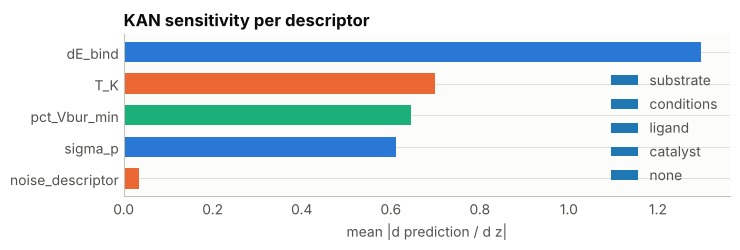

5 descriptors with at least 5 distinct values; 0 with fewer, shown as levels below.


fold envelopes: 20 s


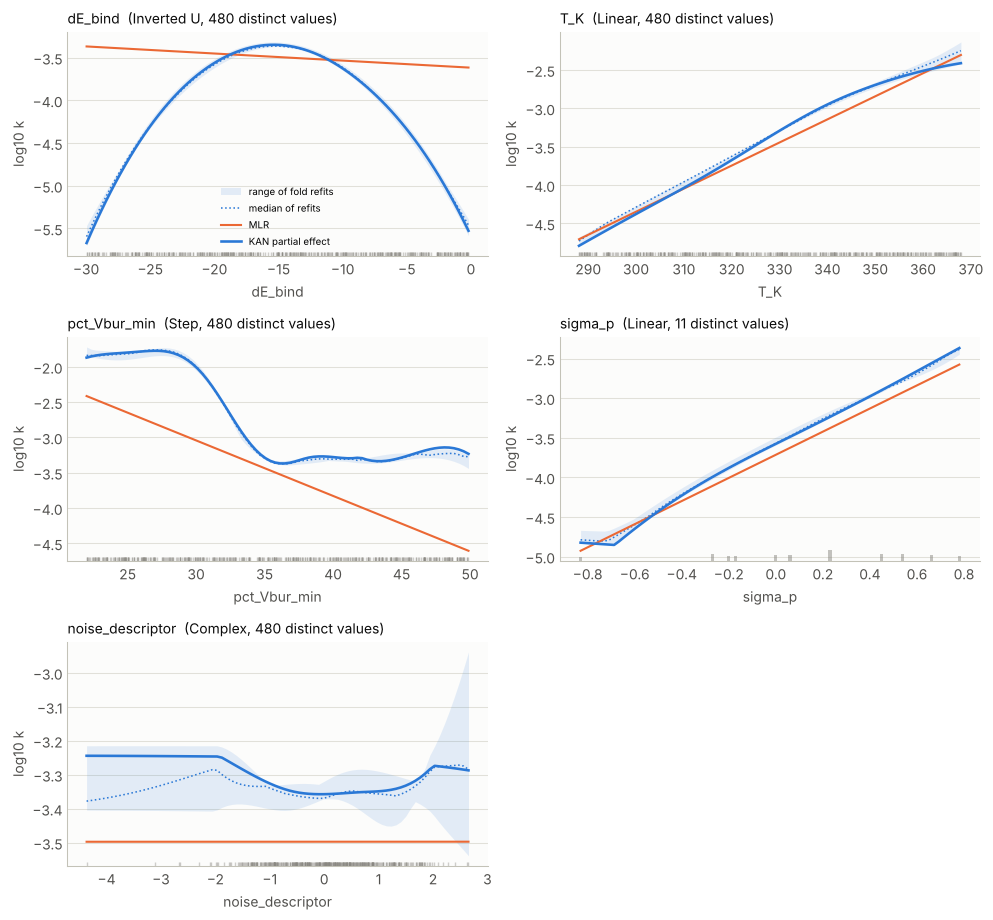

In [7]:
sens = sensitivity(kan, X_tr, task=TASK)
sens_df = pd.DataFrame(
    {"Feature": feature_names, "Component": [COMPONENT[f] for f in feature_names], "Sensitivity": sens}
).sort_values("Sensitivity", ascending=False).reset_index(drop=True)
display(sens_df.round(4))

fig, ax = plt.subplots(figsize=(7.5, 0.28 * n_features + 1.2))
style_axes(ax)
sd = sens_df.iloc[::-1]
ax.barh(sd.Feature, sd.Sensitivity, color=[COMP_COLOR[c] for c in sd.Component], height=0.65, linewidth=0)
for c in COMPONENTS:
    ax.barh([], [], color=COMP_COLOR[c], label=c)
ax.legend(frameon=False, fontsize=8, loc="lower right")
finish_axes(ax, "KAN sensitivity per descriptor", "mean |d prediction / d z|", "")
plt.tight_layout()
plt.show()

# A response curve needs values to interpolate between. Descriptors with fewer
# than five distinct values are handled as levels in the next cell instead.
MIN_LEVELS = 5
rich = [f for f in feature_names if X_df[f].nunique() >= MIN_LEVELS]
few = [f for f in feature_names if f not in rich]
top_features = sens_df[sens_df.Feature.isin(rich)].Feature.head(8).tolist()
TOP_K = len(top_features)
print(f"{len(rich)} descriptors with at least {MIN_LEVELS} distinct values; {len(few)} with fewer, shown as levels below.")
effects = partial_effects(
    kan, X[idx_tr], feature_names, top_features, scaler=scaler, task=TASK,
    extra_models={BASELINE_NAME: baseline},
)  # fmt: skip
t0 = time.time()
effects = partial_effects_cv(
    make_kan, X, y, feature_names, top_features, task=TASK, n_splits=5, random_state=42,
    fit_kwargs={"maxiter": KAN_MAXITER}, effects=effects, verbose=False,
)  # fmt: skip
print(f"fold envelopes: {time.time() - t0:.0f} s")

ncol = 2
nrow = int(np.ceil(TOP_K / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(10, 3.1 * nrow))
for ax, f in zip(np.ravel(axes), top_features):
    plot_partial_effect(ax, effects[f], ylabel=Y_LABEL)
    ax.set_title(f"{f}  ({effects[f].shape(scale=y.std() if TASK == 'regression' else 1.0)[0]}, {effects[f].n_unique} distinct values)", loc="left", fontsize=10)
for ax in np.ravel(axes)[TOP_K:]:
    ax.axis("off")
for ax in np.ravel(axes)[1:TOP_K]:  # one legend is enough
    if ax.get_legend():
        ax.get_legend().remove()
np.ravel(axes)[0].legend(frameon=False, fontsize=7, loc="best")
plt.tight_layout()
plt.show()


In [8]:
# Descriptors with four or fewer levels. A response curve needs a grid; these get a
# table instead: the observed mean per level and the model's mean prediction over the
# same reactions (not at an averaged molecule, which is not a real compound).
if few:
    pred_tr = np.ravel(kan.predict(X_tr))
    rows = []
    for f in few:
        j = feature_names.index(f)
        for lvl in np.unique(X[:, j]):
            at = X[idx_tr, j] == lvl
            rows.append(
                {
                    "Feature": f,
                    "Component": COMPONENT[f],
                    "Level": lvl,
                    "Reactions": int((X[:, j] == lvl).sum()),
                    "Observed mean": float(y[X[:, j] == lvl].mean()),
                    "KAN mean prediction": float(pred_tr[at].mean()) if at.any() else np.nan,
                }
            )
    levels = pd.DataFrame(rows)
    display(levels.round(3))
    spread = levels.groupby("Feature")["Observed mean"].agg(lambda s: s.max() - s.min())
    print("Observed spread across the levels of each few-level descriptor:")
    print(spread.round(1).sort_values(ascending=False).to_string())
else:
    levels = pd.DataFrame()
    print("Every descriptor has at least five distinct values; nothing to show here.")


Every descriptor has at least five distinct values; nothing to show here.


In [9]:
# Shape of the single fit, and whether the five refits agree on it. A curve whose
# range is under 5 % of the target's spread is "Constant" whatever its wiggles.
SHAPE_SCALE = y.std() if TASK == "regression" else 1.0


def stability_table(effects):
    rows = []
    for f, pe in effects.items():
        label, note = pe.shape(scale=SHAPE_SCALE)
        fold_labels = [classify_shape(pe.x_std, c, scale=SHAPE_SCALE)[0] for c in pe.curves]
        agree = float(np.mean([lab == label for lab in fold_labels]))
        width = float(np.mean(pe.hi - pe.lo) / (np.ptp(pe.median) + 1e-9))
        rows.append(
            {
                "Feature": f,
                "Component": COMPONENT[f],
                "Shape": label,
                "Nonlinearity": pe.nonlinearity(),
                "Fold agreement": agree,
                "Envelope / range": width,
                "Fold shapes": ", ".join(fold_labels),
            }
        )
    return pd.DataFrame(rows)


stab = stability_table(effects)
display(stab.round(3))
stable = stab[(stab["Fold agreement"] >= 0.8) & (stab["Envelope / range"] < 0.5)]
print("Shapes that survive refitting (4/5 folds agree, refits disagree by less than half the curve range):")
for _, r in stable.iterrows():
    print(f"  {r.Feature}: {r.Shape}")
print("Shapes that do not:")
for _, r in stab.drop(stable.index).iterrows():
    print(f"  {r.Feature}: single fit {r.Shape}; folds {r['Fold shapes']}")


,Feature,Component,Shape,Nonlinearity,Fold agreement,Envelope / range,Fold shapes
0,dE_bind,catalyst,Inverted U,1.000,1.0,0.044,"Inverted U, Inverted U, Inverted U, Inverted U..."
1,T_K,conditions,Linear,0.110,1.0,0.037,"Linear, Linear, Linear, Linear, Linear"
2,pct_Vbur_min,ligand,Step,0.515,1.0,0.058,"Step, Step, Step, Step, Step"
3,sigma_p,substrate,Linear,0.058,1.0,0.041,"Linear, Linear, Linear, Linear, Linear"
4,noise_descriptor,none,Complex,0.758,0.6,1.541,"Complex, Step, Complex, Complex, Step"


Shapes that survive refitting (4/5 folds agree, refits disagree by less than half the curve range):
  dE_bind: Inverted U
  T_K: Linear
  pct_Vbur_min: Step
  sigma_p: Linear
Shapes that do not:
  noise_descriptor: single fit Complex; folds Complex, Step, Complex, Complex, Step


## 5. Check against the generating equations

Each recovered curve is compared with the exact partial effect of the truth: the term for that
descriptor plus the other terms evaluated at the training means. The linear baseline is on the same
grid. The last cell swaps in the mechanism-break target and asks the same question of the Hammett
curve alone.


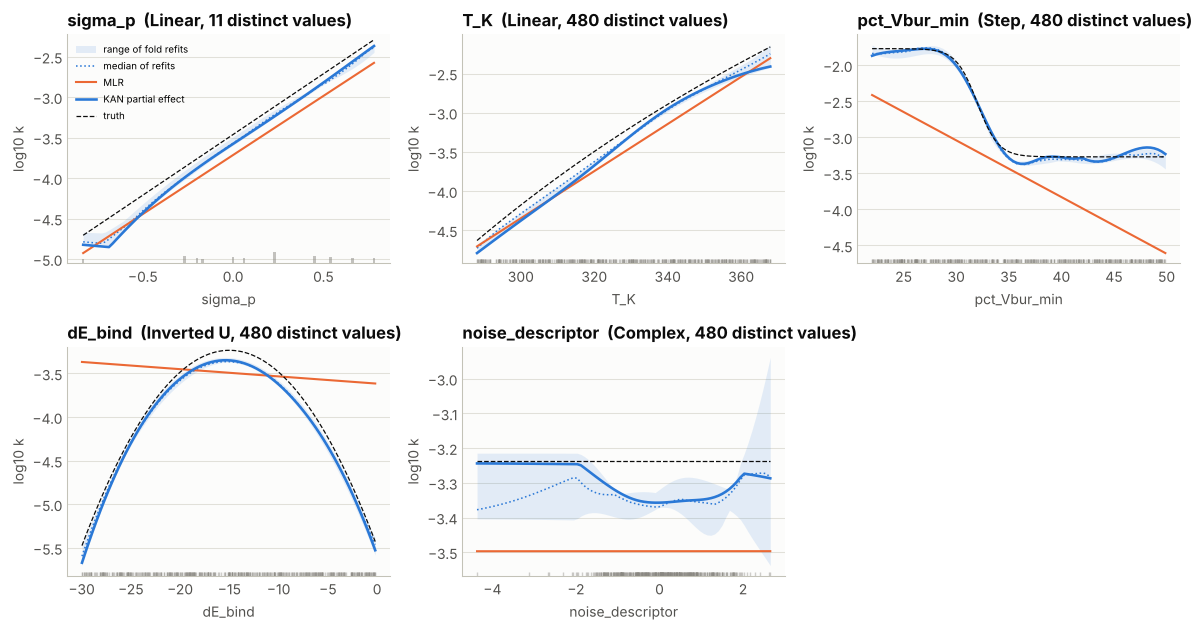

,Feature,True shape,KAN shape,RMSE KAN,RMSE linear,Grid points with data
0,sigma_p,Linear,Linear,0.115,0.259,30
1,T_K,Monotone (concave),Linear,0.158,0.214,80
2,pct_Vbur_min,Step,Step,0.060,0.838,80
3,dE_bind,Inverted U,Inverted U,0.109,0.846,80
4,noise_descriptor,Constant,Complex,0.080,0.259,66


Noise sd in the data: 0.15; a curve within about that of the truth is as good as the data allow.
sigma_p takes 12 values and the grid between NMe2 (-0.83) and OMe (-0.27) has no data; the RMSE skips such points.
Truth cliff at 32.0 %; best single cut on pct_Vbur_min: 32.65 %
KAN curve crosses its midpoint at 32.24 %


In [10]:
mean_tr = X[idx_tr].mean(axis=0)
const = {f: sum(TRUTH[g](mean_tr[j]) for j, g in enumerate(feature_names) if g != f) for f in feature_names}

fig, axes = plt.subplots(2, 3, figsize=(12, 6.4))
err_rows = []
for ax, f in zip(np.ravel(axes), feature_names):
    pe = effects[f] if f in effects else partial_effects(kan, X[idx_tr], feature_names, [f], scaler=scaler, task=TASK, extra_models={BASELINE_NAME: baseline})[f]
    truth = LOG_K0 + const[f] + TRUTH[f](pe.x_raw)
    plot_partial_effect(ax, pe, ylabel=Y_LABEL)
    ax.plot(pe.x_raw, truth, color=INK, linewidth=1.2 * PX, linestyle="--", label="truth", zorder=5)
    # compare only where the data are: grid points within 2 % of the range of an observed value
    supported = np.min(np.abs(pe.x_raw[:, None] - np.unique(pe.support)[None, :]), axis=1) <= 0.02 * np.ptp(pe.x_raw)
    rmse_kan = np.sqrt(np.mean((pe.y - truth)[supported] ** 2))
    rmse_lin = np.sqrt(np.mean((pe.extra[BASELINE_NAME] - truth)[supported] ** 2))
    err_rows.append({"Feature": f, "True shape": {"sigma_p": "Linear", "T_K": "Monotone (concave)", "pct_Vbur_min": "Step", "dE_bind": "Inverted U", "noise_descriptor": "Constant"}[f], "KAN shape": pe.shape(scale=y.std())[0], "RMSE KAN": rmse_kan, "RMSE linear": rmse_lin, "Grid points with data": int(supported.sum())})
for ax in np.ravel(axes)[1:5]:
    if ax.get_legend():
        ax.get_legend().remove()
np.ravel(axes)[0].legend(frameon=False, fontsize=7)
np.ravel(axes)[-1].axis("off")
plt.tight_layout()
plt.show()
check = pd.DataFrame(err_rows)
display(check.round(3))
print(f"Noise sd in the data: {NOISE_SD}; a curve within about that of the truth is as good as the data allow.")
print("sigma_p takes 12 values and the grid between NMe2 (-0.83) and OMe (-0.27) has no data; the RMSE skips such points.")

# The cliff: where did the single-cut search and the KAN put it?
print(f"Truth cliff at 32.0 %; best single cut on pct_Vbur_min: {rules.set_index('Feature').loc['pct_Vbur_min', 'Threshold']:.2f} %")
pe = effects["pct_Vbur_min"]
mid = 0.5 * (pe.y.max() + pe.y.min())
print(f"KAN curve crosses its midpoint at {pe.x_raw[np.argmin(np.abs(pe.y - mid))]:.2f} %")


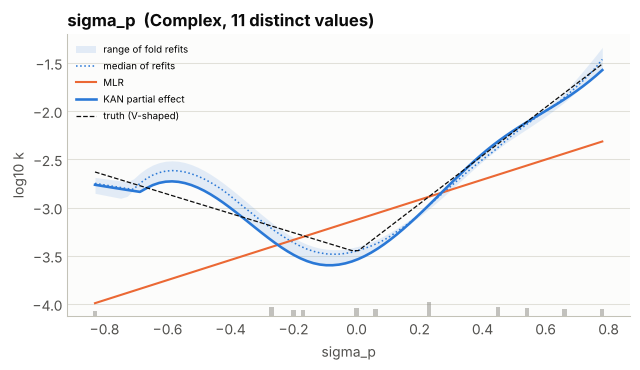

Held-out R2 on the mechanism-break target: KAN 0.979, MLR 0.481
KAN shape on sigma_p: Complex; fold shapes: ['Complex', 'Complex', 'Complex', 'Complex', 'Complex']
RMSE to truth along the grid: KAN 0.120, MLR 0.591


In [11]:
# Mechanism break: rho = -1.0 for sigma < 0 and +2.5 for sigma > 0, everything else unchanged.
def term_vshape(s):
    s = np.asarray(s, dtype=float)
    return np.where(s < 0, -1.0 * s, 2.5 * s)


y_break = LOG_K0 + term_vshape(df.sigma_p) + sum(TRUTH[f](df[f].to_numpy()) for f in TRUTH if f != "sigma_p") + rng.normal(0, NOISE_SD, N)
kan_b = make_kan().fit(X_tr, y_break[idx_tr], maxiter=KAN_MAXITER)
lin_b = LinearRegression().fit(X_tr, y_break[idx_tr])
pe_b = partial_effects(kan_b, X[idx_tr], feature_names, ["sigma_p"], scaler=scaler, task=TASK, extra_models={"MLR": lin_b})
pe_b = partial_effects_cv(make_kan, X, y_break, feature_names, ["sigma_p"], task=TASK, n_splits=5, random_state=42, fit_kwargs={"maxiter": KAN_MAXITER}, effects=pe_b, verbose=False)["sigma_p"]
truth_b = LOG_K0 + sum(TRUTH[g](mean_tr[j]) for j, g in enumerate(feature_names) if g != "sigma_p") + term_vshape(pe_b.x_raw)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
plot_partial_effect(ax, pe_b, ylabel=Y_LABEL)
ax.plot(pe_b.x_raw, truth_b, color=INK, linewidth=1.2 * PX, linestyle="--", label="truth (V-shaped)", zorder=5)
ax.legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()
print(f"Held-out R2 on the mechanism-break target: KAN {r2_score(y_break[idx_te], kan_b.predict(X_te)):.3f}, MLR {r2_score(y_break[idx_te], lin_b.predict(X_te)):.3f}")
print(f"KAN shape on sigma_p: {pe_b.shape(scale=y.std())[0]}; fold shapes: {[classify_shape(pe_b.x_std, c, scale=y.std())[0] for c in pe_b.curves]}")
print(f"RMSE to truth along the grid: KAN {np.sqrt(np.mean((pe_b.y - truth_b) ** 2)):.3f}, MLR {np.sqrt(np.mean((pe_b.extra['MLR'] - truth_b) ** 2)):.3f}")


### Reading

Every term the data generator contains is recovered, and the one term it does not contain is
rejected by the fold envelope rather than by the shape label.

| Term in the generator | True shape | KAN shape (5/5 refits) | RMSE to truth |
|---|---|---|---|
| Hammett, rho = 1.5 | Linear | Linear | 0.115 |
| Eyring, 15 kcal/mol | Monotone, concave | Linear | 0.158 |
| Ligation cliff at 32 % | Step | Step | 0.060 |
| Sabatier volcano, optimum -15 kcal/mol | Inverted U | Inverted U | 0.109 |
| Unrelated descriptor | Constant | Complex | 0.080 |

The noise in the data is 0.15 log units, so every curve is as close to the truth as the data
allow. Three readings follow.

**The cliff lands where it was put.** The generator steps down at 32.0 %; the KAN curve crosses
its midpoint at 32.2 % and the class-balanced stump cuts at 32.6 %. Two independent methods, a
flexible model and a one-parameter rule, agree to within half a percentage point.

**The Eyring term reads as linear, and that is correct here.** Over 288 to 368 K the exact curve
bends by less than the noise, so calling it a line is the honest answer, not a failure. A shape
label is a claim about what the data can support, not about the underlying function.

**The control descriptor is caught by the envelope, not by the label.** The unrelated descriptor
gets a wiggly curve labelled Complex, which on its own looks like a finding. Its fold envelope is
1.5 times the width of the curve itself, against 0.04 to 0.06 for the four real terms, and only
three of five refits agree on the label. That ratio is the test, and it is the reason every
notebook in this series reports it.

**The mechanism break.** With a V-shaped Hammett relationship (rho = -1.0 below sigma = 0 and
+2.5 above it) the KAN reaches R2 0.979 on held-out reactions against 0.481 for the linear model,
and its curve follows the truth to 0.120 RMSE against 0.591. All five refits agree. The label is
"Complex" rather than "U-shaped" because a parabola does not fit a V with two different slopes:
the vocabulary runs out before the curve does, which is why the truth overlay is in the figure.


## 6. Summary dashboard

Four tiles, all from the numbers above: cross-validated score per model, the best single cuts,
the sensitivity grouped by reaction component, and the stability of the top response curves.


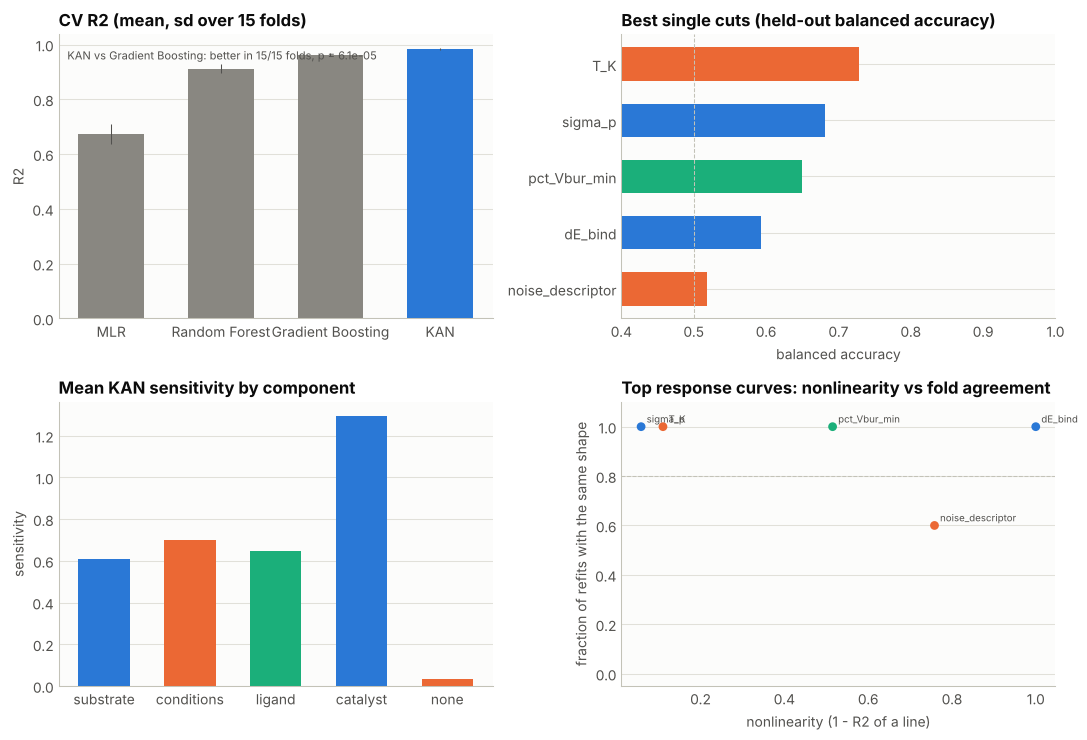

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
ax = axes[0, 0]
style_axes(ax)
s = cv_result.summary
names = list(s.index)
ax.bar(names, s[cv_result.metric + "_mean"], yerr=s[cv_result.metric + "_std"], color=[MUTED] * (len(names) - 1) + [SERIES[0]], width=0.6, linewidth=0, error_kw={"elinewidth": PX, "ecolor": INK_2})
p = cv_result.pairwise
finish_axes(ax, f"CV {cv_result.metric.upper()} (mean, sd over {CV_SPLITS * CV_REPEATS} folds)", "", cv_result.metric.upper())
ax.text(0.02, 0.95, f"KAN vs {p['vs']}: better in {p['wins']}/{p['n']} folds, p = {p['p']:.2g}", transform=ax.transAxes, va="top", fontsize=8, color=INK_2)

ax = axes[0, 1]
style_axes(ax)
top5 = rules.head(5).iloc[::-1]
ax.barh(top5.Feature, top5.Balanced_Acc, color=[COMP_COLOR[COMPONENT[f]] for f in top5.Feature], height=0.6, linewidth=0)
ax.axvline(0.5, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0.4, 1.0)
finish_axes(ax, "Best single cuts (held-out balanced accuracy)", "balanced accuracy", "")

ax = axes[1, 0]
style_axes(ax)
comp_sens = sens_df.groupby("Component")["Sensitivity"].mean().reindex(COMPONENTS)
ax.bar(comp_sens.index, comp_sens.values, color=[COMP_COLOR[c] for c in comp_sens.index], width=0.6, linewidth=0)
finish_axes(ax, "Mean KAN sensitivity by component", "", "sensitivity")

ax = axes[1, 1]
style_axes(ax)
ax.scatter(stab["Nonlinearity"], stab["Fold agreement"], s=40, color=[COMP_COLOR[c] for c in stab.Component], linewidths=0, zorder=3)
for _, r in stab.iterrows():
    ax.annotate(r.Feature, (r.Nonlinearity, r["Fold agreement"]), fontsize=7, color=INK_2, xytext=(4, 3), textcoords="offset points")
ax.axhline(0.8, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_ylim(-0.05, 1.1)
finish_axes(ax, "Top response curves: nonlinearity vs fold agreement", "nonlinearity (1 - R2 of a line)", "fraction of refits with the same shape")
plt.tight_layout()
plt.show()
